# How to use the model

A short tour of `resilience_model.py`. Four examples: one experiment, a one-parameter
sweep, a two-parameter grid, and the manuscript readouts. Each is a few lines.

The model, the baseline parameters, the readouts and the sanity checks all live in that one
file. Nothing else is needed. `README.md` documents the assumptions and the tested range of
every parameter.

Everything here is an example of the calls, not an analysis. Copy whichever cell is closest
to what you want and change the parameters.

## Setup

`check()` runs 15 sanity checks on the model's behaviour. It takes a few seconds, so it is not
run automatically on import. Run it once at the start of a session.

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from resilience_model import run, sweep, grid, check, BASELINE, SAMPLE_HOURS, TESTED_RANGES

mpl.rcParams.update({"figure.dpi": 120, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, RED = "#0072B2", "#E69F00", "#009E73", "#D55E00"

checks = check(verbose=False)
print(f"{int(checks.passed.sum())}/{len(checks)} sanity checks passed")

15/15 sanity checks passed


## The baseline

`BASELINE` holds every default. `run()` with no arguments uses all of them; any parameter I
name is changed and the rest stay put.

In [2]:
print(BASELINE)

Params(seed=42, n_strains=57, focal_index=29, growth_mean=0.55, growth_cv=0.08, food=1.0, half_saturation=0.05, death_rate=0.004, n_resistant=1, focal_multiplier=1.0, resistance_cost=0.05, dose=50.0, gamma=2.5, hill=2.0, susceptible_ic50=5.0, ic50_cv=0.7, vmax=10000.0, km=5.3, initial_biomass=0.005, pregrowth_h=4.0, treatment_h=20.0, dilution=100.0, recovery_h=24.0, cells_per_OD=1000000000.0, detection_rel=0.0001, dt_out=0.1, rtol=1e-08, atol=1e-10)


## Example 1 — one experiment, plotted as a time course

`run()` returns four simulations at once: the resistant community and the matched
all-sensitive community, each treated and untreated. That is the design the protection score
needs, so it is always run.

Below I plot total biomass over time for all four, with the drug and the transfer marked.

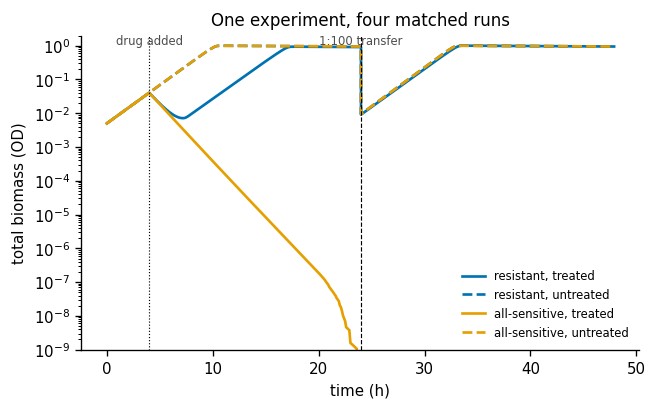

In [3]:
r = run()                      # change anything here, e.g. run(dose=70, growth_mean=0.3)

fig, ax = plt.subplots(figsize=(6, 3.4))
styles = {("resistant", True):  dict(color=BLUE,   ls="-",  label="resistant, treated"),
          ("resistant", False): dict(color=BLUE,   ls="--", label="resistant, untreated"),
          ("sensitive", True):  dict(color=ORANGE, ls="-",  label="all-sensitive, treated"),
          ("sensitive", False): dict(color=ORANGE, ls="--", label="all-sensitive, untreated")}
for key, sim in r.runs.items():
    ax.plot(sim["t"], sim["N"].sum(axis=1), lw=1.6, **styles[key])

ax.axvline(BASELINE.pregrowth_h, color="k", lw=.7, ls=":")
ax.axvline(r.treated["t_transfer"], color="k", lw=.7, ls="--")
ax.annotate("drug added", (BASELINE.pregrowth_h, 1.05), fontsize=7, ha="center", color="0.3")
ax.annotate("1:100 transfer", (r.treated["t_transfer"], 1.05), fontsize=7, ha="center", color="0.3")
ax.set_yscale("log"); ax.set_ylim(1e-9, 2)
ax.set_xlabel("time (h)"); ax.set_ylabel("total biomass (OD)")
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_title("One experiment, four matched runs", fontsize=10)
plt.show()

Per-strain abundances are in `r.timeseries`, at the sampling hours the
protocol uses. Here is the treated resistant community as a stacked area, with the resistant
strain drawn on top.

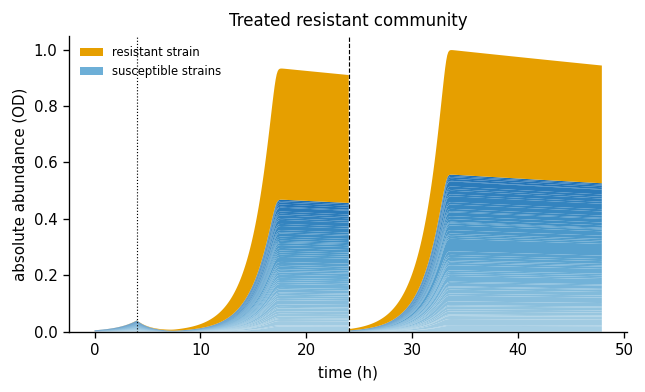

at 48 h the resistant strain is 44.2% of the community


In [4]:
sim = r.treated
carrier = sim["carrier"]
order = list(np.flatnonzero(~carrier)) + list(np.flatnonzero(carrier))
colors = list(plt.cm.Blues(np.linspace(.35, .75, (~carrier).sum()))) + \
         [ORANGE] * carrier.sum()

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.stackplot(sim["t"], sim["N"][:, order].T, colors=colors, linewidth=0)
ax.axvline(BASELINE.pregrowth_h, color="k", lw=.7, ls=":")
ax.axvline(sim["t_transfer"], color="k", lw=.7, ls="--")
ax.set_xlabel("time (h)"); ax.set_ylabel("absolute abundance (OD)")
ax.set_title("Treated resistant community", fontsize=10)
ax.legend(handles=[mpl.patches.Patch(facecolor=ORANGE, label="resistant strain"),
                   mpl.patches.Patch(facecolor=colors[20], label="susceptible strains")],
          fontsize=7, frameon=False, loc="upper left")
plt.show()

print(f"at 48 h the resistant strain is {r.metrics.resistant_share:.1%} of the community")

## Example 2 — a one-parameter sweep

`sweep(parameter, values)` varies one thing and leaves everything else at baseline. It returns
a DataFrame with one row per value: the parameter, then every readout.

`cache="name.csv"` writes the result to a file and reloads it next time, which matters for the
slower sweeps. Delete the file or pass `recompute=True` to run it again.

Any extra keyword arguments are held fixed across the whole sweep, so
`sweep("n_resistant", [...], gamma=4.0)` varies the number of carriers at a killing rate of
4 rather than at the baseline value.

In [5]:
# Extra keyword arguments fix parameters for the whole sweep. Here I make the drug
# harder to survive than at baseline, so that one carrier is not already enough and the
# sweep has something to show.
df = sweep("n_resistant", [1, 2, 4, 8, 16, 32, 56], gamma=4.0, vmax=3000.0,
           cache="example_fraction.csv")
df[["n_resistant", "resistant_fraction", "richness_treated",
    "protected_richness", "resistant_share", "biomass_resilience"]].round(3)

,n_resistant,resistant_fraction,richness_treated,protected_richness,resistant_share,biomass_resilience
0,1.0,0.018,1.0,0.0,1.000,1.000
1,2.0,0.035,35.0,33.0,0.994,0.999
2,4.0,0.070,57.0,53.0,0.964,1.001
3,8.0,0.140,57.0,49.0,0.877,1.002
4,16.0,0.281,57.0,41.0,0.795,1.001
5,32.0,0.561,57.0,25.0,0.781,1.001
6,56.0,0.982,57.0,1.0,0.986,1.000


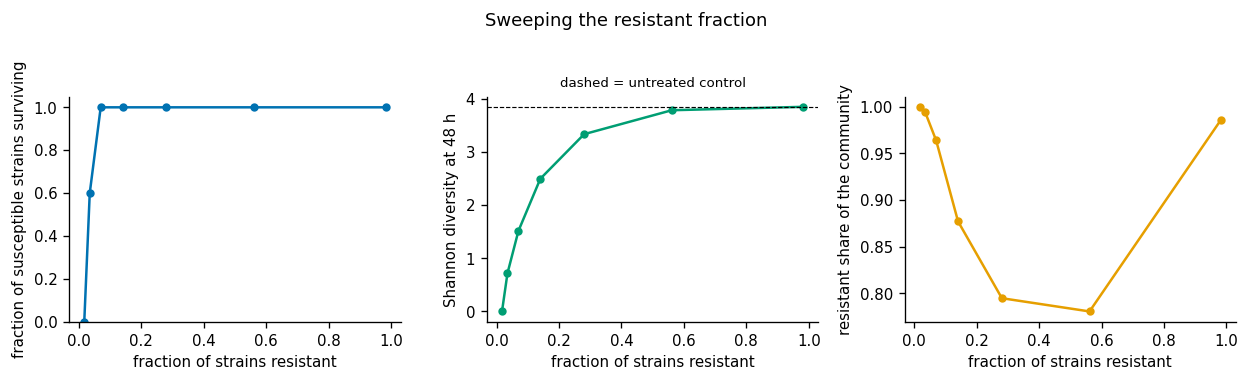

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3))
axs[0].plot(df.resistant_fraction,
            df.protected_richness / df.protected_richness_control, "-o", ms=4, color=BLUE)
axs[0].set_ylim(0, 1.05)
axs[0].set_ylabel("fraction of susceptible strains surviving")
axs[1].plot(df.resistant_fraction, df.shannon_treated, "-o", ms=4, color=GREEN)
axs[1].axhline(df.shannon_control.iloc[0], color="k", lw=.7, ls="--")
axs[1].set_ylabel("Shannon diversity at 48 h")
axs[1].set_title("dashed = untreated control", fontsize=8)
axs[2].plot(df.resistant_fraction, df.resistant_share, "-o", ms=4, color=ORANGE)
axs[2].set_ylabel("resistant share of the community")
for ax in axs:
    ax.set_xlabel("fraction of strains resistant")
fig.suptitle("Sweeping the resistant fraction", y=1.04)
fig.tight_layout()
plt.show()

Any parameter works the same way. A few more, run together so the calls are
visible side by side:

In [7]:
for parameter, values in [("dose", [25, 50, 70, 100, 200]),
                          ("growth_mean", [0.1, 0.3, 0.55, 1.0, 1.4]),
                          ("gamma", [1.0, 1.5, 2.0, 2.5, 3.0])]:
    d = sweep(parameter, values)
    print(f"\n{parameter}")
    print(d[[parameter, "richness_treated", "protected_richness",
             "resistant_share", "biomass_resilience"]].round(3).to_string(index=False))


dose
 dose  richness_treated  protected_richness  resistant_share  biomass_resilience
 25.0              57.0                56.0            0.166               1.000
 50.0              57.0                56.0            0.442               1.001
 70.0              57.0                56.0            0.620               1.001
100.0              57.0                56.0            0.783               1.001
200.0              57.0                56.0            0.948               1.001



growth_mean
 growth_mean  richness_treated  protected_richness  resistant_share  biomass_resilience
        0.10              57.0                56.0            0.537               0.029
        0.30              57.0                56.0            0.622               0.750
        0.55              57.0                56.0            0.442               1.001
        1.00              57.0                56.0            0.102               0.999
        1.40              57.0                56.0            0.014               0.999



gamma
 gamma  richness_treated  protected_richness  resistant_share  biomass_resilience
   1.0              57.0                56.0            0.060               1.000
   1.5              57.0                56.0            0.129               1.000
   2.0              57.0                56.0            0.255               1.000
   2.5              57.0                56.0            0.442               1.001
   3.0              57.0                56.0            0.650               1.001


## Example 3 — two parameters, plotted as a heatmap

`grid(p1, values1, p2, values2)` sweeps a rectangle. The example below is killing against
degradation, 6 x 6, which takes under a minute.

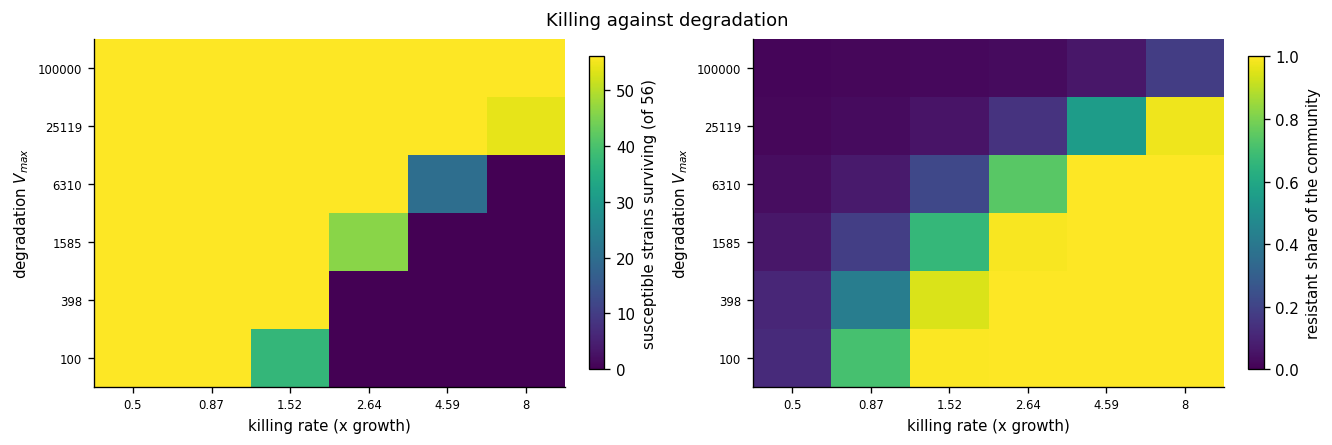

In [8]:
gammas = np.round(np.logspace(np.log10(0.5), np.log10(8), 6), 2)
vmaxes = np.round(np.logspace(2, 5, 6), 0)
g = grid("gamma", gammas, "vmax", vmaxes, cache="example_grid.csv")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for ax, (col, label, kw) in zip(axs, [
        ("protected_richness", "susceptible strains surviving (of 56)", dict(vmin=0, vmax=56)),
        ("resistant_share", "resistant share of the community", dict(vmin=0, vmax=1))]):
    pv = g.pivot_table(index="vmax", columns="gamma", values=col)
    im = ax.pcolormesh(np.arange(pv.shape[1] + 1), np.arange(pv.shape[0] + 1),
                       pv.values, cmap="viridis", shading="flat", **kw)
    ax.set_xticks(np.arange(pv.shape[1]) + .5)
    ax.set_xticklabels([f"{v:g}" for v in pv.columns], fontsize=7)
    ax.set_yticks(np.arange(pv.shape[0]) + .5)
    ax.set_yticklabels([f"{v:g}" for v in pv.index], fontsize=7)
    ax.set_xlabel("killing rate (x growth)"); ax.set_ylabel("degradation $V_{max}$")
    fig.colorbar(im, ax=ax, shrink=.9, label=label)
fig.suptitle("Killing against degradation")
plt.show()

## Example 4 — the manuscript readouts

`r.metrics` is one row holding every readout. The names ending in `_treated` and `_control` are
measured against the matched untreated control at 48 h.

In [9]:
r = run()
manuscript = ["biomass_resilience", "shannon_treated", "shannon_control", "shannon_resilience",
              "richness_treated", "richness_control", "compositional_resilience"]
print("whole community, as reported in the manuscript")
print(r.metrics[manuscript].round(4).to_string())

print("\nthe matched all-sensitive community")
print(r.metrics[["sensitive_biomass_resilience", "sensitive_shannon_treated",
                 "sensitive_richness_treated"]].round(4).to_string())

print("\nextras: the resistant strain, and the strains it is protecting")
print(r.metrics[["resistant_share", "protected_shannon_ratio",
                 "protected_richness", "protected_biomass_ratio"]].round(4).to_string())

whole community, as reported in the manuscript
biomass_resilience           1.0006
shannon_treated              2.8185
shannon_control              3.8506
shannon_resilience           0.7320
richness_treated            57.0000
richness_control            57.0000
compositional_resilience     0.5666

the matched all-sensitive community
sensitive_biomass_resilience    0.0
sensitive_shannon_treated       0.0
sensitive_richness_treated      0.0

extras: the resistant strain, and the strains it is protecting
resistant_share             0.4424
protected_shannon_ratio     0.9979
protected_richness         56.0000
protected_biomass_ratio     0.5647


The protection score is per strain, so it comes back separately. It is
log2 of each strain's treated/untreated response with resistance present, divided by the same
response without it, measured at 24 h. Above zero means the strain did better when the
resistant strain was in the community.

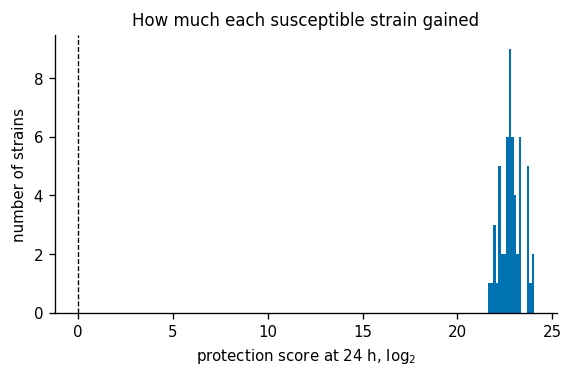

median 22.8  range 21.6 to 24.0
56 of 56 strains more than doubled


In [10]:
fig, ax = plt.subplots(figsize=(5.4, 3))
ax.hist(r.protection, bins=18, color=BLUE)
ax.axvline(0, color="k", lw=.8, ls="--")
ax.set_xlabel("protection score at 24 h, $\\log_2$")
ax.set_ylabel("number of strains")
ax.set_title("How much each susceptible strain gained", fontsize=10)
plt.show()

print(f"median {r.protection.median():.1f}  "
      f"range {r.protection.min():.1f} to {r.protection.max():.1f}")
print(f"{(r.protection > 1).sum()} of {len(r.protection)} strains more than doubled")

Per-strain abundances at each sampling hour are in `r.timeseries`, in long
form, ready for grouping or pivoting.

In [11]:
print(r.timeseries.head(4).to_string(index=False))

pivot = (r.timeseries[(r.timeseries.community == "resistant") & r.timeseries.treated]
         .pivot_table(index="strain", columns="hour", values="relative"))
print("\nrelative abundance of the five most abundant strains at 48 h")
print(pivot.sort_values(48.0, ascending=False).head(5).round(4).to_string())

community  treated  hour strain  carrier  absolute  relative
resistant     True   4.0    k01    False  0.000733  0.018163
resistant     True   4.0    k02    False  0.000589  0.014608
resistant     True   4.0    k03    False  0.000792  0.019627
resistant     True   4.0    k04    False  0.000819  0.020303

relative abundance of the five most abundant strains at 48 h
hour      4.0     6.0     24.0    48.0
strain                                
k30     0.0167  0.1809  0.4985  0.4424
k31     0.0255  0.0160  0.0192  0.0442
k03     0.0196  0.0161  0.0165  0.0212
k47     0.0201  0.0157  0.0154  0.0207
k01     0.0182  0.0173  0.0192  0.0206


## What we can change

`BASELINE` lists every parameter with its units. `TESTED_RANGES` gives the span over which each
one has been exercised — outside those the solver may struggle or the biology stops making
sense.

In [12]:
print(pd.Series({k: f"{lo:g} to {hi:g}" for k, (lo, hi) in TESTED_RANGES.items()},
                name="tested range").to_string())

growth_mean            0.02 to 1.8
growth_cv                 0 to 0.6
food                      0.2 to 5
half_saturation        0.01 to 0.5
death_rate          0.0005 to 0.02
n_resistant                1 to 57
focal_multiplier           1 to 30
resistance_cost           0 to 0.5
dose                      5 to 500
gamma                    0.3 to 30
hill                        1 to 4
susceptible_ic50           1 to 20
ic50_cv                 0.1 to 1.2
vmax                  10 to 100000
km                       0.5 to 50
initial_biomass     0.0001 to 0.05
dilution                10 to 1000
